In [11]:
import pandas as pd

dataArt = pd.read_csv("finalScoresArt.csv", index_col="neighborhood")
dataCrime = pd.read_csv("finalScoresCriminalActivity.tsv", sep="\t", index_col="Neighborhood")
dataParks = pd.read_csv("finalScoresPlaygrounds.csv", index_col="neighborhood")

crimeRank = dataCrime["Score"].rank(ascending=True, pct=True) * 100

#print(crimeRank.head(10))

combined = pd.DataFrame({
    "art": dataArt["artFinalScore"],
    "crime": crimeRank,
    "parks": dataParks["numParks"]
})

combined["overallScore"] = (
    combined["art"] * 0.2 +
   combined["crime"] * 0.5 +
   combined["parks"] * 0.3
)

combined = combined.sort_values(
    "overallScore",
    ascending=False
)

print(combined.head(50))

                                art      crime       parks  overallScore
Allegheny Center          96.363636  51.648352   93.382353     73.111609
Beltzhoover               65.545455  57.142857   93.382353     69.695225
Elliott                   73.545455  54.945055   84.558824     67.549265
Highland Park             93.090909  41.758242   93.382353     67.512009
Upper Lawrenceville       27.090909  67.032967   84.558824     64.302312
East Carnegie             27.090909  95.604396   29.411765     62.043909
Beechview                 82.181818  31.868132   97.794118     61.708665
Swisshelm Park            20.727273  94.505495   29.411765     60.221731
Spring Garden             49.181818  82.417582   29.411765     59.868684
Duquesne Heights          65.545455  74.725275   29.411765     59.295258
Regent Square             20.727273  92.307692   29.411765     59.122830
South Side Slopes         72.090909  29.670330   97.794118     58.591582
Esplen                    20.727273  90.109890   29

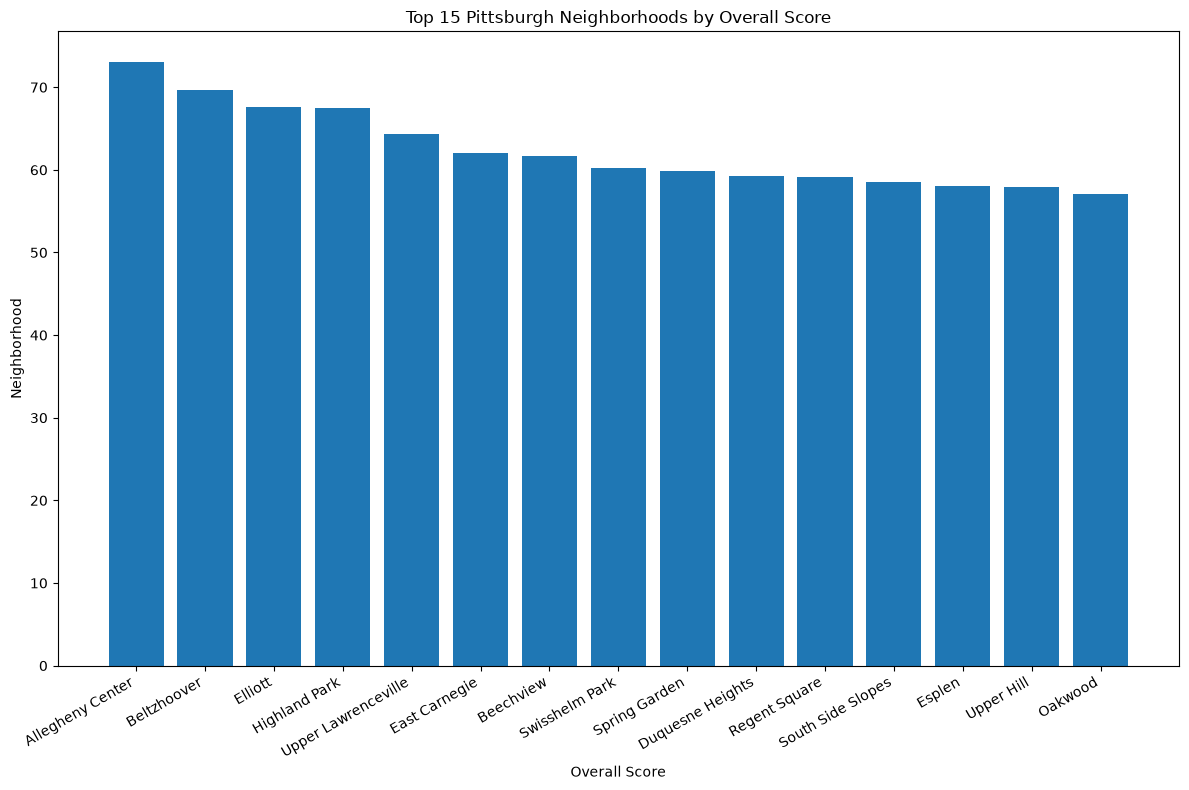

In [13]:
import matplotlib.pyplot as plt

graph = combined.sort_values(
    by="overallScore",
    ascending=False
).head(15)

graph = graph.reset_index()

plt.figure(figsize=(12, 8))

plt.bar(
    graph["index"],
    graph["overallScore"]
)

plt.xlabel("Overall Score")
plt.ylabel("Neighborhood")
plt.title("Top 15 Pittsburgh Neighborhoods by Overall Score")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

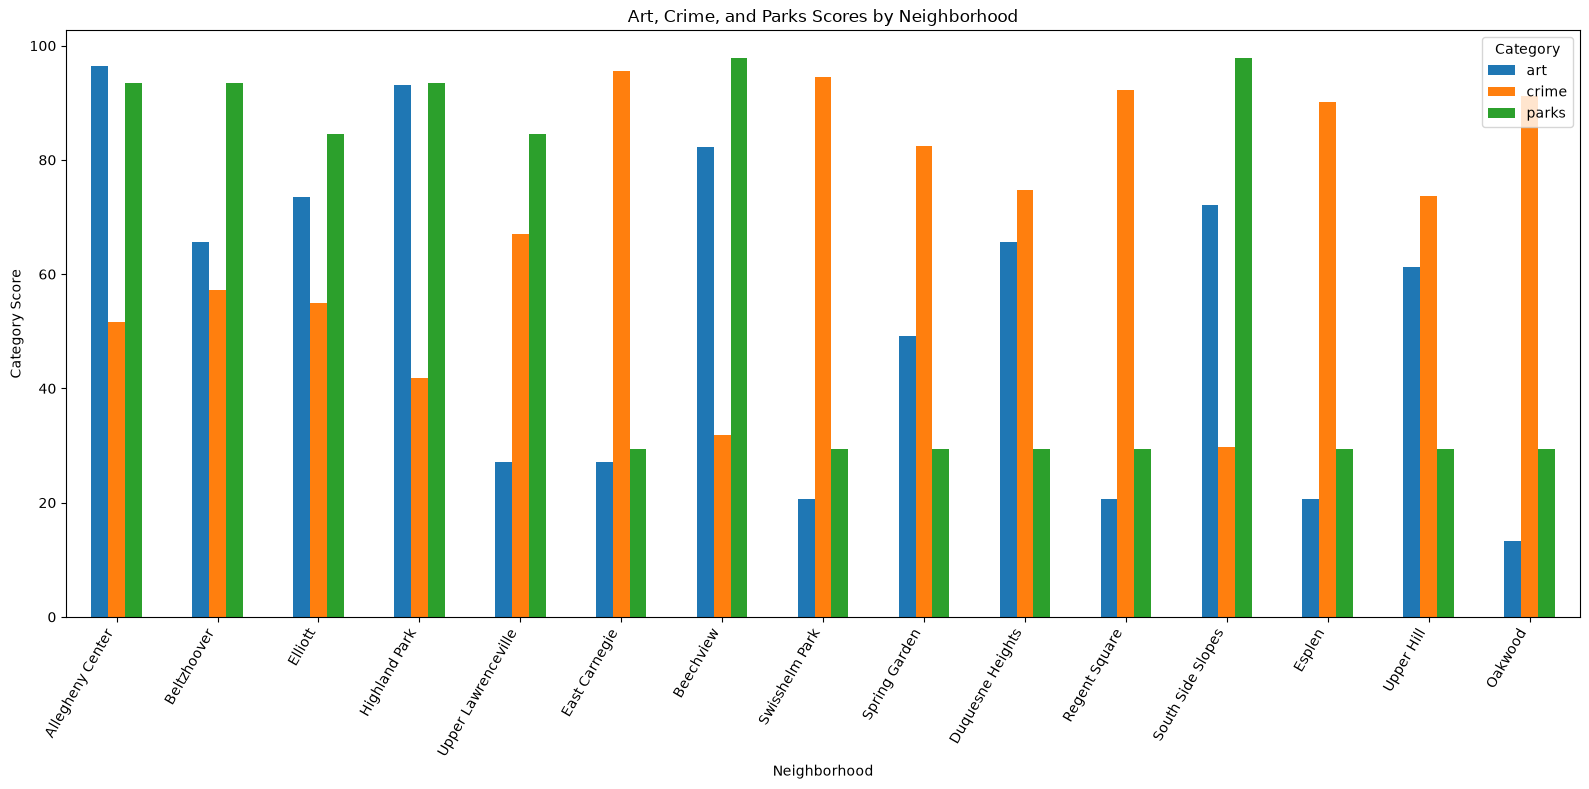

In [19]:
top15 = combined.sort_values(
    by="overallScore",
    ascending=False
).head(15)

top15 = top15.reset_index()

top15.plot(
    x="index",
    y=["art", "crime", "parks"],
    kind="bar",
    figsize=(16, 8)
)

plt.xlabel("Neighborhood")
plt.ylabel("Category Score")
plt.title("Art, Crime, and Parks Scores by Neighborhood")
plt.xticks(rotation=60, ha="right")
plt.legend(title="Category")
plt.tight_layout()
plt.show()